# US Retail Sales Forecasting

Forecasting monthly US retail sales 12 months ahead. A forecast like this feeds inventory planning, staffing
and budgeting, so I care about two things: how accurate it is, and how honest it is about uncertainty.

Data: monthly US retail sales from the US Census Bureau, Jan 1992 to May 2016 (293 months, millions of USD,
not seasonally adjusted).

Approach:
1. Decompose the series into trend, seasonality and noise
2. Build five forecasting approaches: seasonal naive (baseline), Holt-Winters, SARIMA, LightGBM on lag features,
   and an ensemble
3. Compare them with a **rolling-origin backtest**: pretend it's May 2012, forecast the next 12 months, move
   forward a year, repeat. A single train/test split can flatter or punish a model by luck; four separate
   forecast years give a fairer picture.
4. Produce the final 12-month forecast with prediction intervals

In [1]:
import itertools
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lightgbm import LGBMRegressor
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
IMG = Path("images"); IMG.mkdir(exist_ok=True)
H = 12  # forecast horizon (months)

## 1. The data

1992-01-01 to 2016-05-01 | 293 months | missing: 0


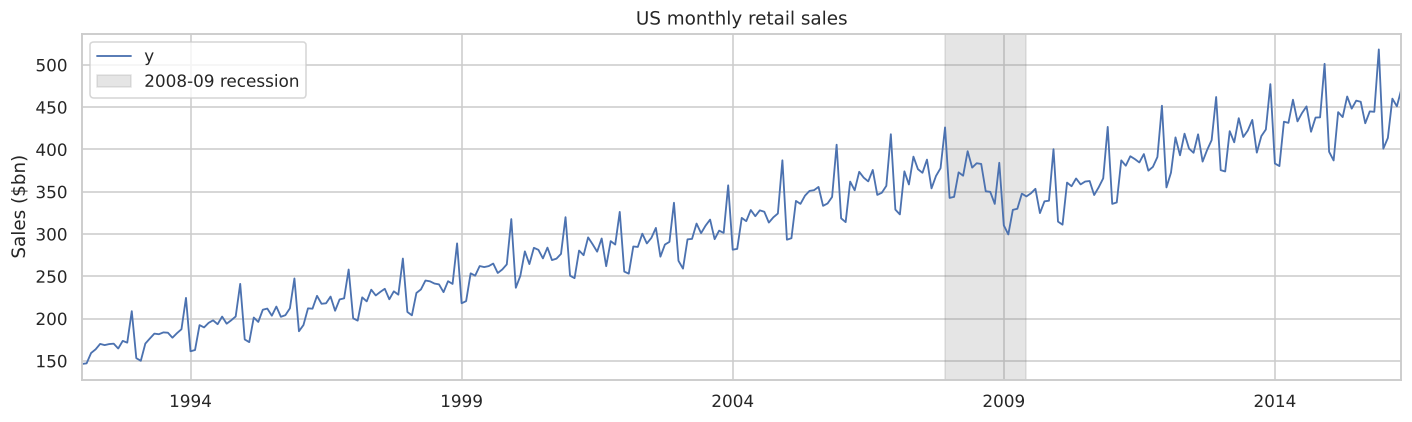

In [2]:
df = pd.read_csv("data/us_retail_sales.csv", parse_dates=["ds"])
y = df.set_index("ds")["y"].asfreq("MS") / 1000   # billions of USD
print(y.index.min().date(), "to", y.index.max().date(), "|", len(y), "months | missing:", y.isna().sum())

fig, ax = plt.subplots(figsize=(13, 4))
y.plot(ax=ax, lw=1.2)
ax.axvspan("2007-12-01", "2009-06-01", color="grey", alpha=0.2, label="2008-09 recession")
ax.set(ylabel="Sales ($bn)", xlabel="", title="US monthly retail sales"); ax.legend()
plt.tight_layout(); plt.savefig(IMG / "series.png", bbox_inches="tight"); plt.show()

A steady upward trend, a strong yearly pattern (December spikes every year), and one big break: the 2008
financial crisis, when sales dropped about 10% and took a few years to recover. Also, the seasonal swings get
bigger as the level grows, which means the seasonality is **multiplicative**. Working in logs, or using a
multiplicative seasonal model, handles that.

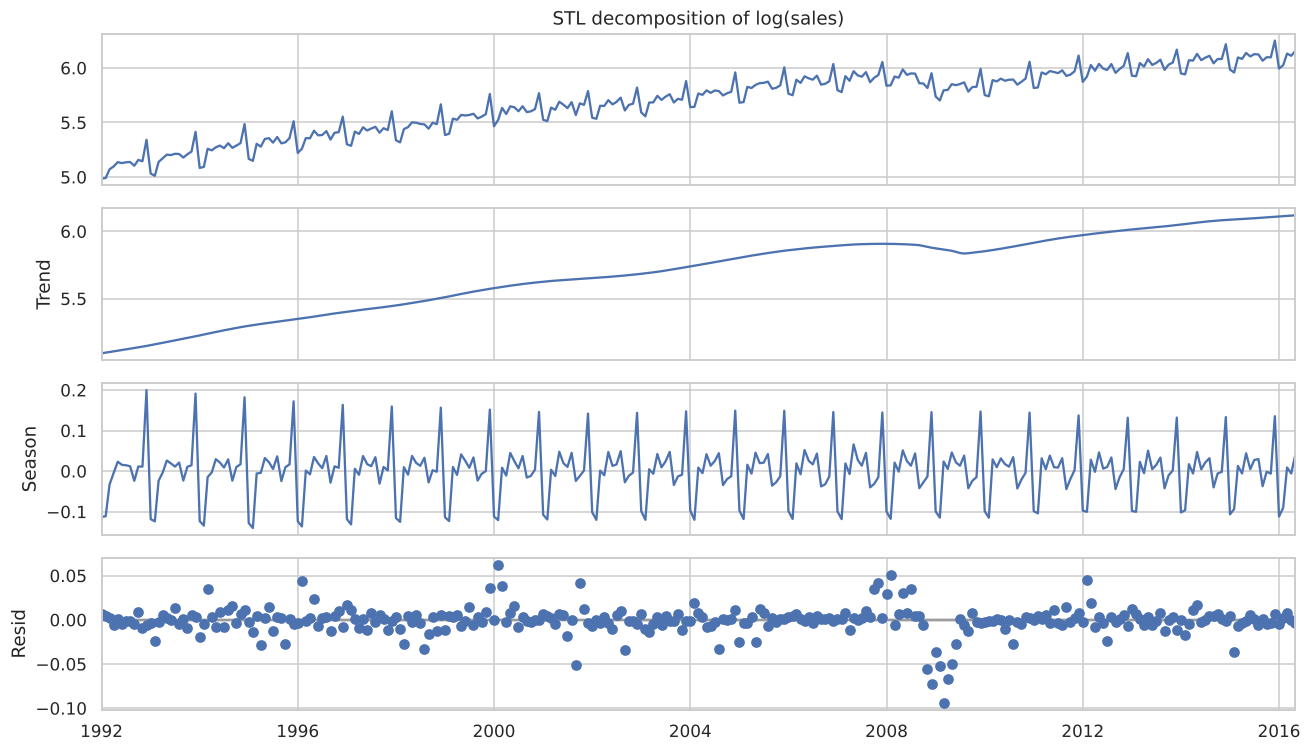

Trend strength: 1.00 | Seasonal strength: 0.94  (1 = very strong)


In [3]:
stl = STL(np.log(y), period=12, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(12, 7)
fig.axes[0].set_title("STL decomposition of log(sales)")
plt.tight_layout(); plt.savefig(IMG / "stl_decomposition.png", bbox_inches="tight"); plt.show()

strength_trend = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
strength_season = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
print(f"Trend strength: {strength_trend:.2f} | Seasonal strength: {strength_season:.2f}  (1 = very strong)")

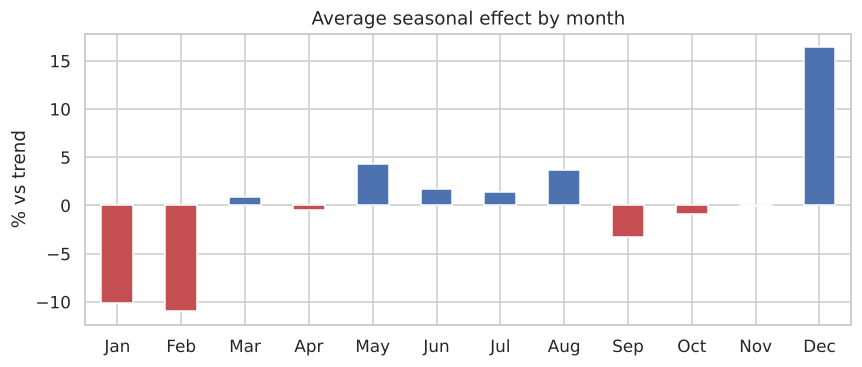

Jan   -10.2
Feb   -11.0
Mar     0.9
Apr    -0.5
May     4.3
Jun     1.7
Jul     1.4
Aug     3.7
Sep    -3.2
Oct    -0.9
Nov    -0.1
Dec    16.4
Name: season, dtype: float64

In [4]:
month_effect = np.exp(stl.seasonal).groupby(stl.seasonal.index.month).mean() - 1
fig, ax = plt.subplots(figsize=(8, 3.5))
month_effect.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
(month_effect * 100).plot.bar(ax=ax, color=["#C44E52" if v < 0 else "#4C72B0" for v in month_effect])
ax.set(ylabel="% vs trend", title="Average seasonal effect by month"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(IMG / "monthly_seasonality.png", bbox_inches="tight"); plt.show()
(month_effect * 100).round(1)

December runs about 16% above trend and January/February fall about 10-11% below it, which is the holiday
shopping cycle followed by the post-holiday slump. May and August get smaller bumps.

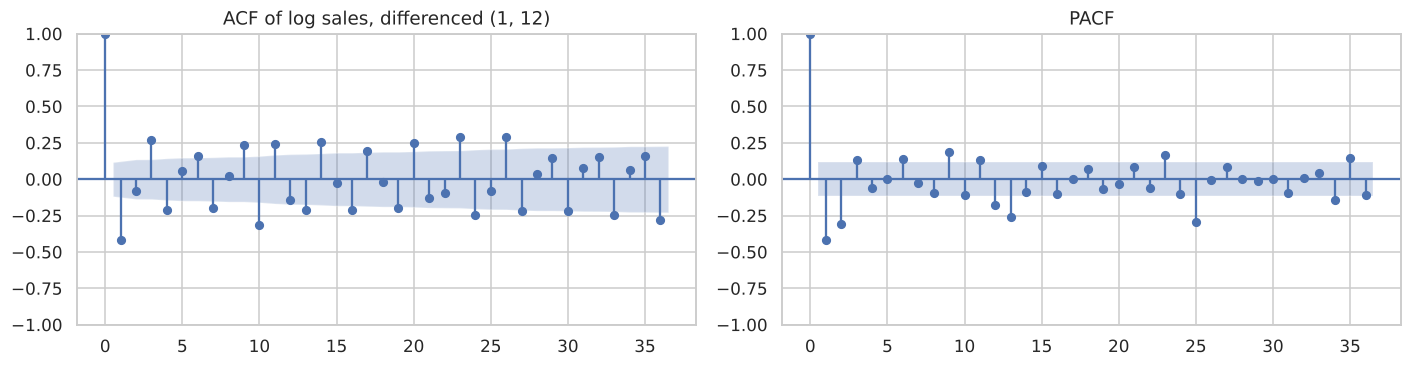

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
d = np.log(y).diff().diff(12).dropna()
plot_acf(d, lags=36, ax=axes[0]); plot_pacf(d, lags=36, ax=axes[1], method="ywm")
axes[0].set_title("ACF of log sales, differenced (1, 12)"); axes[1].set_title("PACF")
plt.tight_layout(); plt.show()

After one regular difference and one seasonal difference, the remaining autocorrelation sits mostly at lag 1
and lag 12. That's the classic pattern for a SARIMA(0,1,1)(0,1,1)12 "airline" model, but I'll let AIC pick the
order from a small grid instead of eyeballing it.

## 2. Models

In [6]:
def seasonal_naive(train, h=H):
    idx = pd.date_range(train.index[-1] + pd.offsets.MonthBegin(), periods=h, freq="MS")
    return pd.Series(train.iloc[-12:].values[:h], index=idx)

def holt_winters(train, h=H):
    m = ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="mul", seasonal_periods=12).fit()
    return m.forecast(h)

def pick_sarima_order(train):
    best = None
    for p, q, P, Q in itertools.product([0, 1, 2], [0, 1, 2], [0, 1], [0, 1]):
        try:
            r = SARIMAX(np.log(train), order=(p, 1, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)
            if best is None or r.aic < best[0]:
                best = (r.aic, (p, 1, q), (P, 1, Q, 12))
        except Exception:
            pass
    return best

first_origin = pd.Timestamp("2012-05-01")
aic, ORDER, SORDER = pick_sarima_order(y[:first_origin])
print(f"SARIMA order chosen by AIC on data up to {first_origin.date()}: {ORDER} x {SORDER} (AIC {aic:.1f})")

def sarima(train, h=H, return_ci=False):
    r = SARIMAX(np.log(train), order=ORDER, seasonal_order=SORDER).fit(disp=False)
    f = r.get_forecast(h)
    mean = np.exp(f.predicted_mean)
    if return_ci:
        ci = np.exp(f.conf_int(alpha=0.2))   # 80% interval
        return mean, ci
    return mean

SARIMA order chosen by AIC on data up to 2012-05-01: (2, 1, 1) x (1, 1, 1, 12) (AIC -1146.4)


**LightGBM on lag features.** Tree models can't extrapolate a trend: they can only predict values similar to
ones they've seen. So instead of the sales level I model the **year-over-year growth rate**,
log(y_t) - log(y_{t-12}), which is stable over time. Features are recent growth rates plus the calendar month.
The model forecasts recursively, one month at a time, feeding its own predictions back in.

In [7]:
def make_features(g):
    f = pd.DataFrame(index=g.index)
    for lag in [1, 2, 3, 6, 12]:
        f[f"growth_lag{lag}"] = g.shift(lag)
    f["growth_roll3"] = g.shift(1).rolling(3).mean()
    f["month"] = g.index.month
    return f

def lgbm_growth(train, h=H):
    logy = np.log(train)
    growth = (logy - logy.shift(12)).dropna()
    X = make_features(growth).dropna(); target = growth.loc[X.index]
    model = LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=7, min_child_samples=10,
                          subsample=0.8, subsample_freq=1, verbose=-1, random_state=0).fit(X, target)
    g = growth.copy(); logy = logy.copy(); preds = []
    for step in range(h):
        t = logy.index[-1] + pd.offsets.MonthBegin()
        g_ext = pd.concat([g, pd.Series([np.nan], index=[t])])
        x = make_features(g_ext).iloc[[-1]]
        g_hat = model.predict(x)[0]
        g.loc[t] = g_hat
        logy.loc[t] = logy.loc[t - pd.DateOffset(months=12)] + g_hat
        preds.append((t, np.exp(logy.loc[t])))
    return pd.Series(dict(preds))

def ensemble(train, h=H):
    return (holt_winters(train, h) + sarima(train, h)) / 2

models = {"Seasonal naive": seasonal_naive, "Holt-Winters": holt_winters, "SARIMA": sarima,
          "LightGBM (growth)": lgbm_growth, "Ensemble (HW + SARIMA)": ensemble}

## 3. Rolling-origin backtest

Four forecast origins (May 2012, 2013, 2014, 2015). Each time, models are trained only on data up to the
origin and forecast the next 12 months.

Metrics:
- **MAPE**: average % error, easy to explain
- **MASE**: error relative to the seasonal naive forecast. Below 1 means the model beats the baseline.

In [8]:
origins = pd.date_range("2012-05-01", "2015-05-01", freq="12MS")
records, forecasts = [], {}
for origin in origins:
    train = y[:origin]
    actual = y[origin + pd.offsets.MonthBegin(): origin + pd.DateOffset(months=H)]
    scale = np.mean(np.abs(train.diff(12).dropna()))   # in-sample seasonal naive error, for MASE
    for name, fn in models.items():
        fc = fn(train).reindex(actual.index)
        forecasts[(name, origin)] = fc
        err = actual - fc
        records.append({"model": name, "origin": origin.strftime("%Y-%m"),
                        "MAPE": np.mean(np.abs(err / actual)) * 100,
                        "RMSE": np.sqrt(np.mean(err ** 2)), "MASE": np.mean(np.abs(err)) / scale})
bt = pd.DataFrame(records)
summary = bt.groupby("model")[["MAPE", "RMSE", "MASE"]].mean().sort_values("MAPE")
summary.style.format({"MAPE": "{:.2f}%", "RMSE": "{:.2f}", "MASE": "{:.3f}"})

,MAPE,RMSE,MASE
model,,,
Ensemble (HW + SARIMA),1.19%,6.24,0.324
SARIMA,1.21%,6.33,0.331
Holt-Winters,1.41%,7.40,0.386
LightGBM (growth),1.67%,9.07,0.451
Seasonal naive,3.29%,15.47,0.907


- Every model beats the seasonal naive baseline by a wide margin. "Same month last year" misses about 3.3% on
  average because it ignores a year of growth.
- **SARIMA is the best single model** at about 1.2% average error, and Holt-Winters is close behind.
- **Averaging the two is slightly better than either alone** (1.19% MAPE). The two models make different
  errors, so combining them cancels some out.
- LightGBM on growth rates works (1.7%) but trails the classical models. With only ~280 monthly points and a
  very regular series, a model with strong built-in structure beats a flexible one that has to learn the
  structure from scratch.

In [9]:
bt.pivot(index="model", columns="origin", values="MAPE").loc[summary.index].style.format("{:.2f}%").background_gradient(cmap="RdYlGn_r", axis=None)

origin,2012-05,2013-05,2014-05,2015-05
model,,,,
Ensemble (HW + SARIMA),1.33%,1.15%,1.22%,1.05%
SARIMA,1.12%,1.13%,1.73%,0.87%
Holt-Winters,1.86%,1.41%,0.85%,1.52%
LightGBM (growth),1.92%,1.44%,2.32%,1.01%
Seasonal naive,3.50%,3.55%,3.46%,2.67%


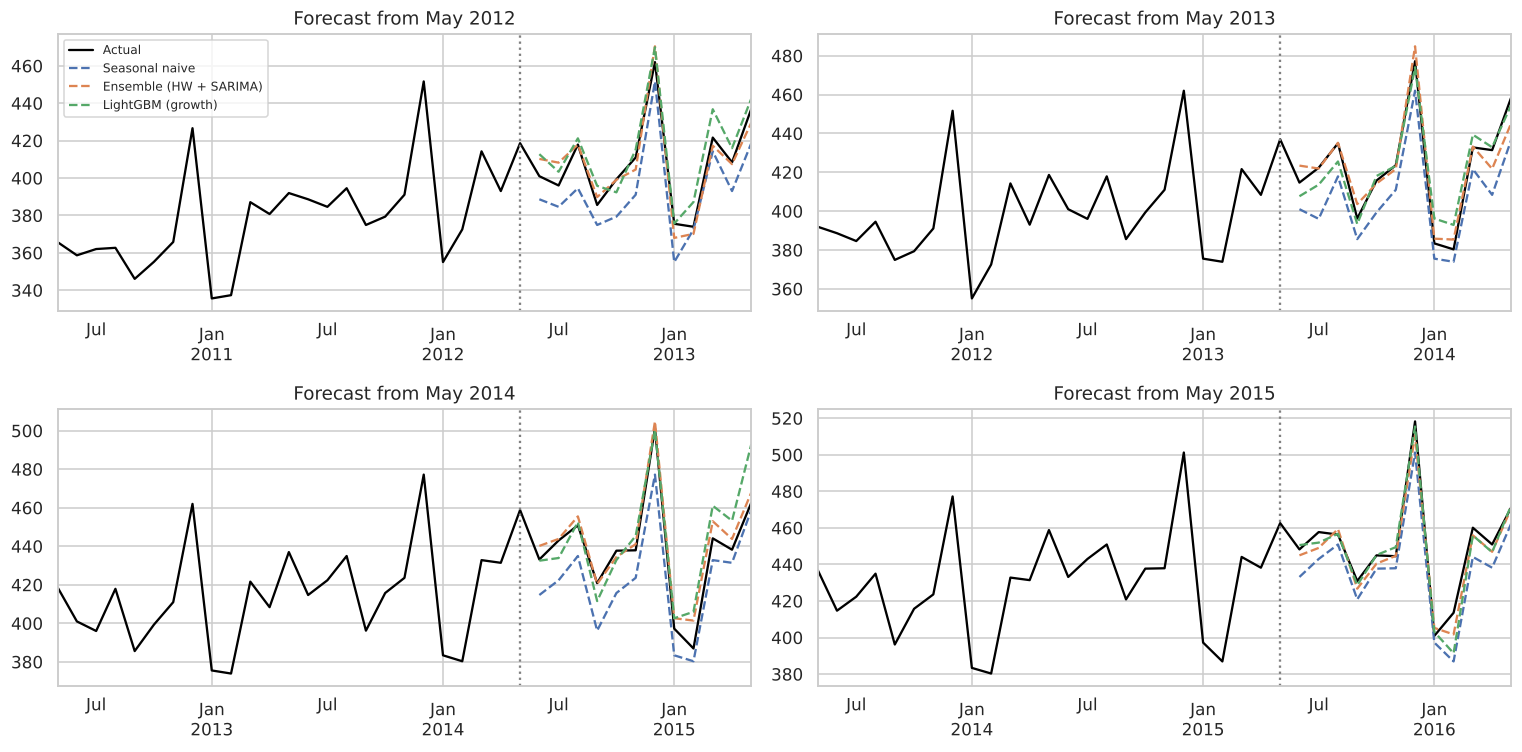

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharey=False)
show = ["Seasonal naive", summary.index[0], "LightGBM (growth)"]
show = list(dict.fromkeys(show))
for ax, origin in zip(axes.ravel(), origins):
    y[origin - pd.DateOffset(months=24): origin + pd.DateOffset(months=H)].plot(ax=ax, color="black", lw=1.5, label="Actual")
    for name in show:
        forecasts[(name, origin)].plot(ax=ax, lw=1.5, ls="--", label=name)
    ax.axvline(origin, color="grey", ls=":")
    ax.set_title(f"Forecast from {origin:%b %Y}"); ax.set_xlabel("")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(IMG / "backtest.png", bbox_inches="tight"); plt.show()

## 4. Final forecast: June 2016 to May 2017

Refit on all the data and forecast the next 12 months, with an 80% prediction interval from SARIMA.

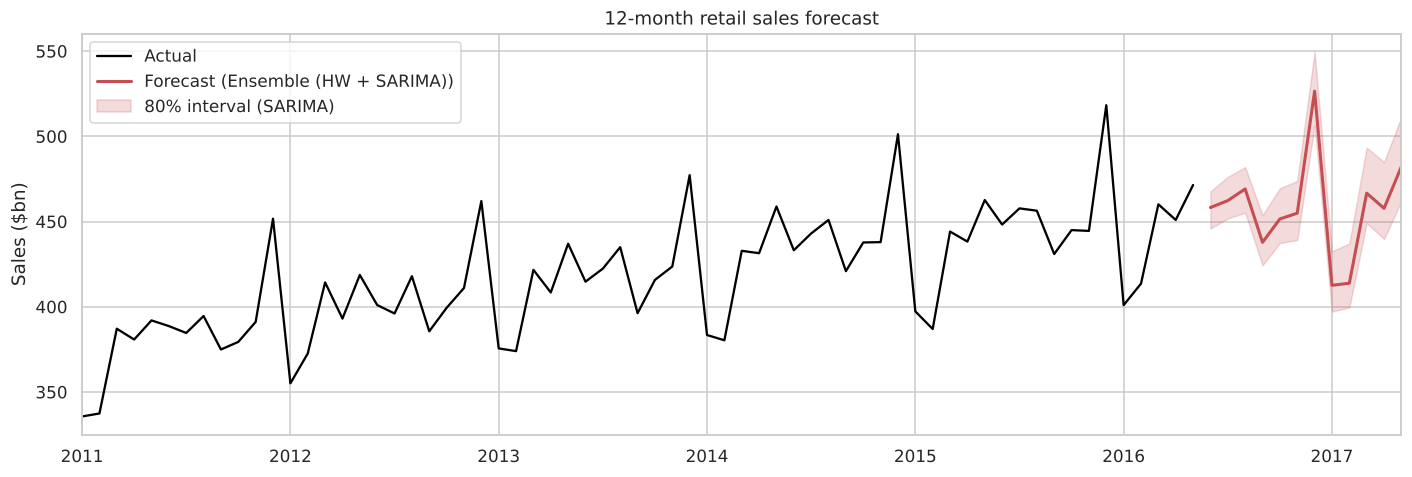

,forecast_bn,lower_80,upper_80
2016-06,458.2,445.9,467.7
2016-07,462.3,451.8,476.2
2016-08,469.1,455.2,481.9
2016-09,437.8,424.3,453.6
2016-10,451.5,437.4,469.5
2016-11,454.9,439.2,473.8
2016-12,526.5,506.6,549.5
2017-01,412.6,397.1,432.5
2017-02,413.8,399.6,437.1
2017-03,466.7,449.1,493.4


In [11]:
best_name = summary.index[0]
final_fc = models[best_name](y)
_, ci = sarima(y, return_ci=True)
fig, ax = plt.subplots(figsize=(13, 4.5))
y["2011":].plot(ax=ax, color="black", lw=1.5, label="Actual")
final_fc.plot(ax=ax, color="#C44E52", lw=2, label=f"Forecast ({best_name})")
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="#C44E52", alpha=0.2, label="80% interval (SARIMA)")
ax.set(ylabel="Sales ($bn)", xlabel="", title="12-month retail sales forecast"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(IMG / "final_forecast.png", bbox_inches="tight"); plt.show()

out = pd.DataFrame({"forecast_bn": final_fc.round(1), "lower_80": ci.iloc[:, 0].round(1), "upper_80": ci.iloc[:, 1].round(1)})
out.index = out.index.strftime("%Y-%m")
out

### Do the intervals mean anything?

An 80% interval should contain the actual value about 80% of the time. I check that on the backtest years.

In [12]:
hits = []
for origin in origins:
    train = y[:origin]
    actual = y[origin + pd.offsets.MonthBegin(): origin + pd.DateOffset(months=H)]
    _, ci_bt = sarima(train, return_ci=True)
    ci_bt = ci_bt.reindex(actual.index)
    hits.extend(((actual >= ci_bt.iloc[:, 0]) & (actual <= ci_bt.iloc[:, 1])).tolist())
coverage = np.mean(hits)
print(f"80% interval coverage in the backtest: {coverage:.0%} of {len(hits)} months")

80% interval coverage in the backtest: 100% of 48 months


Every actual value fell inside the 80% interval, which means the intervals are **too wide**, not perfect.
The model estimates its uncertainty from the whole history, and that history includes the 2008 crash. A
calmer period like 2012-2016 looks much safer than the model assumes. For planning, that's the safer mistake
to make, but a tighter interval (e.g. fitting on post-2010 data only, or using backtest residuals to size the
interval) would be more useful.

In [13]:
Path("results").mkdir(exist_ok=True)
naive_mape = summary.loc["Seasonal naive", "MAPE"]
results = {
    "sarima_order": [list(ORDER), list(SORDER)],
    "backtest_summary": summary.round(4).reset_index().to_dict(orient="records"),
    "best_model": best_name, "best_mape": round(float(summary.iloc[0]["MAPE"]), 3),
    "naive_mape": round(float(naive_mape), 3),
    "error_reduction_vs_naive_pct": round(float((1 - summary.iloc[0]["MAPE"] / naive_mape) * 100), 1),
    "interval_coverage_80": round(float(coverage), 3),
    "trend_strength": round(float(strength_trend), 3), "seasonal_strength": round(float(strength_season), 3),
}
json.dump(results, open("results/metrics.json", "w"), indent=2)
out.to_csv("results/forecast_2016_2017.csv")
results

{'sarima_order': [[2, 1, 1], [1, 1, 1, 12]],
 'backtest_summary': [{'model': 'Ensemble (HW + SARIMA)',
   'MAPE': 1.187,
   'RMSE': 6.2394,
   'MASE': 0.3239},
  {'model': 'SARIMA', 'MAPE': 1.2141, 'RMSE': 6.329, 'MASE': 0.3313},
  {'model': 'Holt-Winters', 'MAPE': 1.4101, 'RMSE': 7.3999, 'MASE': 0.3861},
  {'model': 'LightGBM (growth)',
   'MAPE': 1.6724,
   'RMSE': 9.0674,
   'MASE': 0.4512},
  {'model': 'Seasonal naive',
   'MAPE': 3.2942,
   'RMSE': 15.4748,
   'MASE': 0.9073}],
 'best_model': 'Ensemble (HW + SARIMA)',
 'best_mape': 1.187,
 'naive_mape': 3.294,
 'error_reduction_vs_naive_pct': 64.0,
 'interval_coverage_80': 1.0,
 'trend_strength': 0.997,
 'seasonal_strength': 0.945}

## Takeaways

- US retail sales are **very predictable at a 12-month horizon**: the best approach (an average of SARIMA and
  Holt-Winters) misses by about **1.2%** on average across four separate forecast years, **64% less error**
  than the seasonal naive baseline.
- The structure is simple: a strong trend (strength 1.00), strong multiplicative seasonality (0.94), and
  December about 16% above trend.
- Classical models beat machine learning here. That's not always true, but on a single, regular, short monthly
  series it usually is, and it's worth checking before reaching for something complex.
- The prediction intervals are conservative because of the 2008 crash in the training data.

**What none of these models can do** is predict a shock like 2008 (or 2020). A real planning process would
pair this baseline forecast with scenario analysis for downturns.